# 🎬 Système de Recommandation de Films
## Machine Learning Non Supervisé — Filtrage Collaboratif & Factorisation Matricielle (SVD)

**Auteur :** Osemes — L2 Big Data / Informatique, DIT Dakar  
**Objectif :** Proposer des films pertinents à un utilisateur en se basant sur ses évaluations passées et celles d'utilisateurs similaires.

---

### Techniques implémentées
| Technique | Description |
|---|---|
| **Content-Based Filtering** | Recommandation par similarité de contenu (genres, acteurs, réalisateur) |
| **User-Based Collaborative Filtering** | Similarité cosinus entre profils d'utilisateurs |
| **Item-Based Collaborative Filtering** | Similarité entre films basée sur les évaluations |
| **Factorisation Matricielle (SVD)** | Décomposition SVD via la librairie `Surprise` |

### Métriques d'évaluation
- **RMSE** (Root Mean Squared Error) — erreur quadratique moyenne
- **MAE** (Mean Absolute Error) — erreur absolue moyenne  
- **Précision@K** — fraction de recommandations pertinentes dans le top-K
- **Recall@K** — fraction de films pertinents effectivement recommandés

---

## 1. Importation des Bibliothèques

In [1]:
import pandas as pd
import numpy as np
import ast
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity, linear_kernel
from sklearn.preprocessing import MinMaxScaler

from surprise import SVD, SVDpp, NMF, KNNBasic, KNNWithMeans, Dataset, Reader, accuracy
from surprise.model_selection import cross_validate, train_test_split, GridSearchCV

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

## 2. Chargement & Inspection des Données

Les données proviennent du **MovieLens / TMDB** dataset, composé de deux fichiers :
- `movies_metadata.csv` — métadonnées de 45 466 films (budget, genres, note, etc.)
- `credits.csv` — casting et équipe technique (acteurs, réalisateur)

In [2]:
# Chargement des données
df_movies  = pd.read_csv("movies_metadata.csv", low_memory=False)
df_credits = pd.read_csv("credits.csv")

print("=== movies_metadata.csv ===")
print(f"  Dimensions : {df_movies.shape[0]:,} lignes × {df_movies.shape[1]} colonnes")
print(f"  Colonnes   : {df_movies.columns.tolist()}")
print()
print("=== credits.csv ===")
print(f"  Dimensions : {df_credits.shape[0]:,} lignes × {df_credits.shape[1]} colonnes")
print(f"  Colonnes   : {df_credits.columns.tolist()}")

=== movies_metadata.csv ===
  Dimensions : 45,466 lignes × 24 colonnes
  Colonnes   : ['adult', 'belongs_to_collection', 'budget', 'genres', 'homepage', 'id', 'imdb_id', 'original_language', 'original_title', 'overview', 'popularity', 'poster_path', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'video', 'vote_average', 'vote_count']

=== credits.csv ===
  Dimensions : 45,476 lignes × 3 colonnes
  Colonnes   : ['cast', 'crew', 'id']


In [3]:
# Affichage d'un aperçu
df_movies.head()

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,popularity,poster_path,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",21.946943,/rhIRbceoE9lR4veEXuwCC2wARtG.jpg,"[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-10-30,373554033.0000,81.0000,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7000,5415.0000
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,17.015539,/vzmL6fP7aPKNKPRTFnZmiUfciyV.jpg,"[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-12-15,262797249.0000,104.0000,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9000,2413.0000
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,11.7129,/6ksm1sjKMFLbO7UY2i6G1ju9SML.jpg,"[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-12-22,0.0000,101.0000,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5000,92.0000
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",3.859495,/16XOMpEaLWkrcPqSQqhTmeJuqQl.jpg,[{'name': 'Twentieth Century Fox Film Corporat...,"[{'iso_3166_1': 'US', 'name': 'United States o...",1995-12-22,81452156.0000,127.0000,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1000,34.0000
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,8.387519,/e64sOI48hQXyru7naBFyssKFxVd.jpg,"[{'name': 'Sandollar Productions', 'id': 5842}...","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-02-10,76578911.0000,106.0000,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7000,173.0000


In [4]:
# Statistiques descriptives des colonnes numériques clés
df_movies[['budget','revenue','runtime','vote_average','vote_count','popularity']].describe()

,revenue,runtime,vote_average,vote_count
count,45460.0000,45203.0000,45460.0000,45460.0000
mean,11209348.5393,94.1282,5.6182,109.8973
std,64332246.7407,38.4078,1.9242,491.3104
min,0.0000,0.0000,0.0000,0.0000
25%,0.0000,85.0000,5.0000,3.0000
50%,0.0000,95.0000,6.0000,10.0000
75%,0.0000,107.0000,6.8000,34.0000
max,2787965087.0000,1256.0000,10.0000,14075.0000


In [5]:
# Valeurs manquantes
missing = df_movies.isnull().sum().sort_values(ascending=False)
print("Valeurs manquantes (top 10) :")
print(missing[missing > 0].head(10))

Valeurs manquantes (top 10) :
belongs_to_collection    40972
homepage                 37684
tagline                  25054
overview                   954
poster_path                386
runtime                    263
status                      87
release_date                87
imdb_id                     17
original_language           11
dtype: int64


## 3. Nettoyage des Données & Fusion des Datasets

Plusieurs colonnes contiennent des **données JSON imbriquées** (genres, cast, crew) sous forme de chaînes de caractères. Nous devons les parser correctement.

In [6]:
# Conversion de la colonne 'id' (certaines valeurs non numériques)
df_movies['id'] = pd.to_numeric(df_movies['id'], errors='coerce')

# Fusion des deux datasets sur 'id'
df = df_movies.merge(df_credits, on='id')

print(f"Dataset fusionné : {df.shape[0]:,} films × {df.shape[1]} colonnes")
print(f"Doublons détectés : {df.duplicated(subset='id').sum()}")

# Suppression des doublons éventuels
df = df.drop_duplicates(subset='id')
print(f"Après nettoyage  : {df.shape[0]:,} films")

Dataset fusionné : 45,538 films × 26 colonnes
Doublons détectés : 106
Après nettoyage  : 45,432 films


In [7]:
# ── Parsing des colonnes JSON imbriquées ──────────────────────────────────────

def parse_names(json_str, key='name', limit=None):
    """Extrait les valeurs d'une clé depuis une liste JSON imbriquée."""
    try:
        items = ast.literal_eval(str(json_str))
        names = [item[key] for item in items if key in item]
        return names[:limit] if limit else names
    except (ValueError, TypeError):
        return []

def get_director(crew_str):
    """Extrait le nom du réalisateur depuis la colonne 'crew'."""
    try:
        for member in ast.literal_eval(str(crew_str)):
            if member.get('job') == 'Director':
                return member.get('name', '')
    except (ValueError, TypeError):
        pass
    return ''

# Application
df['genres_list']  = df['genres'].apply(lambda x: parse_names(x, limit=3))
df['cast_list']    = df['cast'].apply(lambda x: parse_names(x, limit=5))
df['director']     = df['crew'].apply(get_director)
df['keywords_list']= df['genres'].apply(lambda x: parse_names(x, limit=5))  # proxy

print("Exemple — genres :", df['genres_list'].iloc[0])
print("Exemple — cast   :", df['cast_list'].iloc[0])
print("Exemple — director:", df['director'].iloc[0])

Exemple — genres : ['Animation', 'Comedy', 'Family']
Exemple — cast   : ['Tom Hanks', 'Tim Allen', 'Don Rickles', 'Jim Varney', 'Wallace Shawn']
Exemple — director: John Lasseter


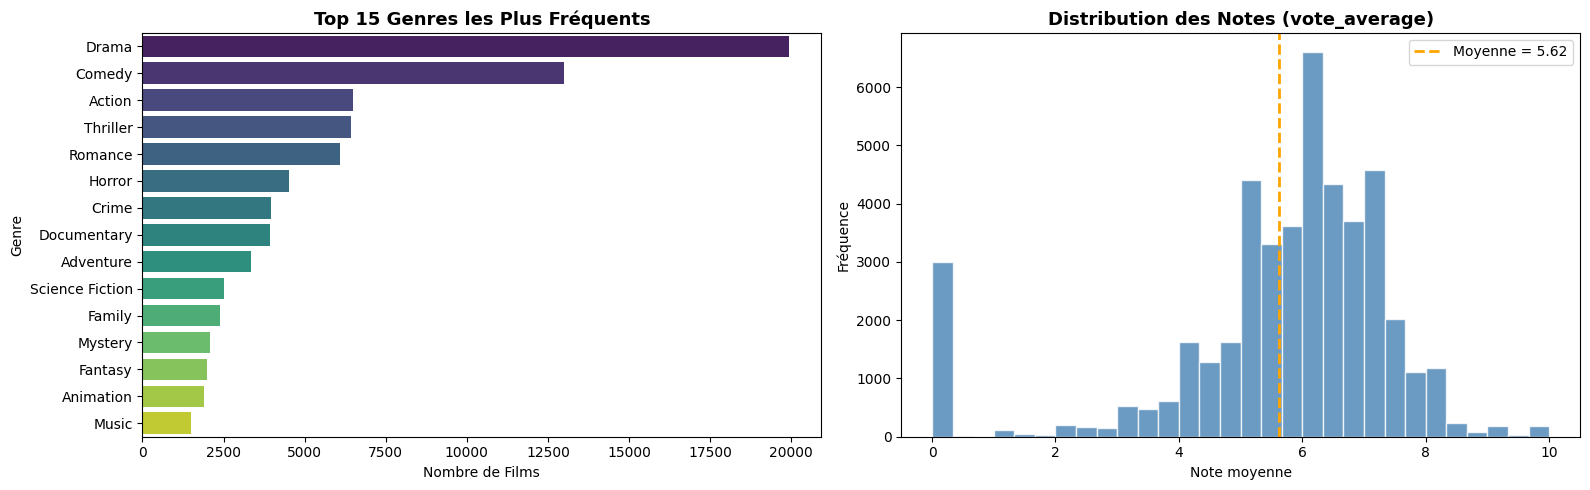

Graphiques sauvegardés


In [8]:
# ── Distribution des genres ───────────────────────────────────────────────────
from collections import Counter

all_genres = [g for sublist in df['genres_list'] for g in sublist]
genre_counts = Counter(all_genres)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Barplot genres
genres_df = pd.DataFrame(genre_counts.most_common(15), columns=['Genre', 'Count'])
sns.barplot(data=genres_df, x='Count', y='Genre', palette='viridis', ax=axes[0])
axes[0].set_title('Top 15 Genres les Plus Fréquents', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Nombre de Films')

# Distribution des notes
axes[1].hist(df['vote_average'].dropna(), bins=30, color='steelblue', edgecolor='white', alpha=0.8)
axes[1].axvline(df['vote_average'].mean(), color='orange', linestyle='--', linewidth=2,
                label=f'Moyenne = {df["vote_average"].mean():.2f}')
axes[1].set_title('Distribution des Notes (vote_average)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Note moyenne')
axes[1].set_ylabel('Fréquence')
axes[1].legend()

plt.tight_layout()
plt.savefig('distribution_genres_notes.png', dpi=120, bbox_inches='tight')
plt.show()
print("Graphiques sauvegardés")

## 4. Recommandation par Note Pondérée (Baseline — Formule IMDB)

Avant d'implémenter le filtrage collaboratif, nous établissons un **classement de référence** basé sur la formule IMDB :

$$\text{Score} = \frac{v}{v+m} \cdot R + \frac{m}{v+m} \cdot C$$

- $v$ = nombre de votes du film  
- $m$ = seuil minimum de votes (percentile 90)  
- $R$ = note moyenne du film  
- $C$ = note moyenne globale sur l'ensemble du dataset

In [9]:
# Calcul des paramètres IMDB
C = df['vote_average'].mean()           # Note moyenne globale
m = df['vote_count'].quantile(0.90)     # Seuil = 90e percentile

print(f"Note moyenne globale (C) : {C:.4f}")
print(f"Seuil minimum de votes (m) : {m:.0f}")

# Films éligibles (vote_count >= m)
df_eligible = df[df['vote_count'] >= m].copy()
print(f"Films éligibles : {len(df_eligible):,} / {len(df):,}")

def weighted_rating(row, m=m, C=C):
    v = row['vote_count']
    R = row['vote_average']
    return (v / (v + m)) * R + (m / (v + m)) * C

df_eligible['imdb_score'] = df_eligible.apply(weighted_rating, axis=1)

# Top 15
top15 = df_eligible.sort_values('imdb_score', ascending=False)[
    ['title', 'imdb_score', 'vote_average', 'vote_count', 'genres_list']
].head(15)

print("\n=== TOP 15 Films (Score Pondéré IMDB) ===")
print(top15.to_string(index=False))

Note moyenne globale (C) : 5.6185
Seuil minimum de votes (m) : 160
Films éligibles : 4,551 / 45,432

=== TOP 15 Films (Score Pondéré IMDB) ===
                          title  imdb_score  vote_average  vote_count                          genres_list
       The Shawshank Redemption      8.4459        8.5000   8358.0000                       [Drama, Crime]
                  The Godfather      8.4254        8.5000   6024.0000                       [Drama, Crime]
    Dilwale Dulhania Le Jayenge      8.4215        9.1000    661.0000             [Comedy, Drama, Romance]
                The Dark Knight      8.2655        8.3000  12269.0000               [Drama, Action, Crime]
                     Fight Club      8.2564        8.3000   9678.0000                              [Drama]
                   Pulp Fiction      8.2514        8.3000   8670.0000                    [Thriller, Crime]
               Schindler's List      8.2066        8.3000   4436.0000                [Drama, History, War]
 

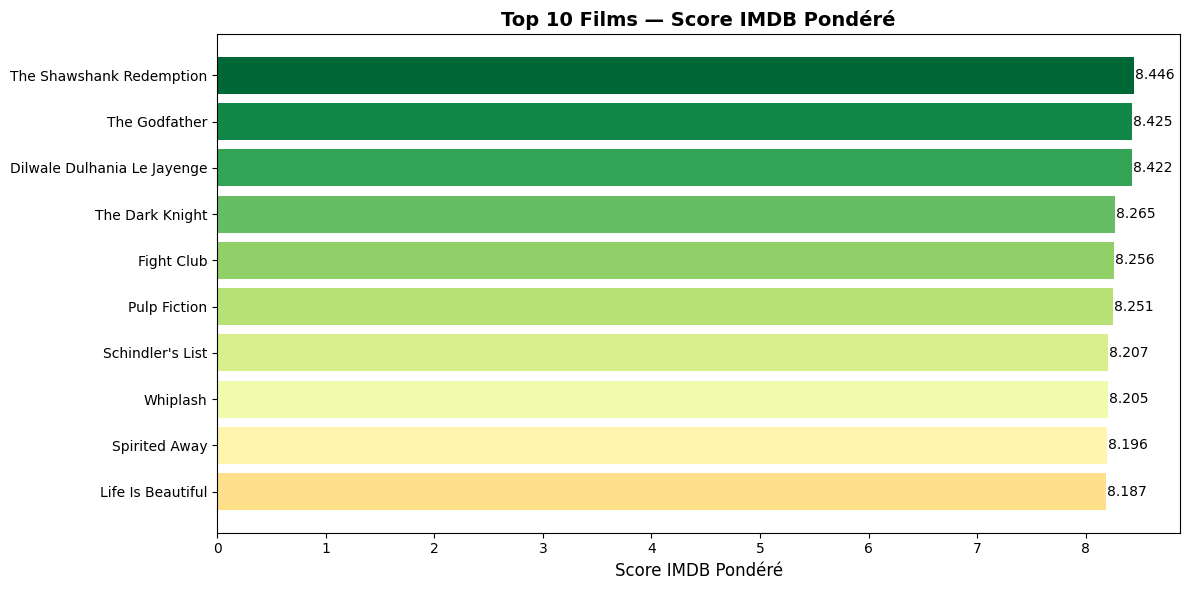

In [10]:
# Visualisation top 10
top10 = top15.head(10)
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(top10['title'][::-1], top10['imdb_score'][::-1],
               color=plt.cm.RdYlGn(np.linspace(0.4, 1, 10)))
ax.set_xlabel('Score IMDB Pondéré', fontsize=12)
ax.set_title('Top 10 Films — Score IMDB Pondéré', fontsize=14, fontweight='bold')
for bar, score in zip(bars, top10['imdb_score'][::-1]):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
            f'{score:.3f}', va='center', fontsize=10)
plt.tight_layout()
plt.savefig('top10_imdb.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Filtrage Basé sur le Contenu (Content-Based Filtering)

Le filtrage basé sur le contenu recommande des films **similaires à un film donné** selon ses attributs : synopsis, genres, acteurs, réalisateur.

### 5.1 — Approche TF-IDF sur les Synopsis (Overview)
La matrice TF-IDF transforme les descriptions textuelles en vecteurs numériques. La **similarité cosinus** mesure alors la proximité entre deux films.

In [11]:
# ── TF-IDF sur les synopsis ───────────────────────────────────────────────────
df_cb = df_eligible[['id','title','overview','genres_list','cast_list','director']].copy()
df_cb = df_cb.dropna(subset=['overview'])
df_cb = df_cb.reset_index(drop=True)

print(f"Films utilisés pour le content-based : {len(df_cb):,}")

# Vectorisation TF-IDF
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=10_000,
    ngram_range=(1, 2)
)
tfidf_matrix = tfidf.fit_transform(df_cb['overview'])
print(f"Matrice TF-IDF : {tfidf_matrix.shape}")

# Similarité cosinus
cosine_sim_tfidf = linear_kernel(tfidf_matrix, tfidf_matrix)
print(f"Matrice de similarité cosinus : {cosine_sim_tfidf.shape}")

# Index inversé titre → position
indices = pd.Series(df_cb.index, index=df_cb['title'].str.lower()).drop_duplicates()

def recommend_content_tfidf(title, n=10):
    """Recommande des films similaires via TF-IDF + similarité cosinus."""
    title_lower = title.lower()
    if title_lower not in indices:
        return f"Film '{title}' non trouvé."
    idx = indices[title_lower]
    sim_scores = list(enumerate(cosine_sim_tfidf[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)[1:n+1]
    movie_indices = [s[0] for s in sim_scores]
    result = df_cb.iloc[movie_indices][['title','genres_list']].copy()
    result['similarité'] = [round(s[1], 4) for s in sim_scores]
    return result

# Test
print("\n🎬 Recommandations pour 'The Dark Knight' :")
print(recommend_content_tfidf('The Dark Knight', n=8).to_string(index=False))

Films utilisés pour le content-based : 4,546
Matrice TF-IDF : (4546, 10000)
Matrice de similarité cosinus : (4546, 4546)

🎬 Recommandations pour 'The Dark Knight' :
                                  title                genres_list  similarité
                  The Dark Knight Rises     [Action, Crime, Drama]      0.3426
                         Batman Forever   [Action, Crime, Fantasy]      0.2730
                         Batman Returns          [Action, Fantasy]      0.2233
             Batman: Under the Red Hood        [Action, Animation]      0.1971
                                    JFK [Drama, Thriller, History]      0.1788
                                 Batman          [Fantasy, Action]      0.1683
Batman: The Dark Knight Returns, Part 2        [Action, Animation]      0.1680
Batman: The Dark Knight Returns, Part 1        [Action, Animation]      0.1662


### 5.2 — Approche Métadonnées Enrichies (Cast + Genres + Réalisateur)

Nous construisons une **"soupe" de métadonnées** combinant genres, acteurs principaux et réalisateur pour capturer des similarités plus fines.

In [12]:
# 🔥 ÉTAPE CRUCIALE : On réaligne le dictionnaire 'indices' sur les positions physiques de df_cb
# Cela garantit que chaque titre correspond exactement à sa ligne (0, 1, 2...) dans df_cb et count_matrix
df_cb = df_cb.reset_index(drop=True)  # Optionnel mais fortement recommandé pour éviter les décalages
indices = pd.Series(df_cb.index, index=df_cb['title'].str.lower()).to_dict()

# ── Métadonnées enrichies ─────────────────────────────────────────────────────
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def clean_name(name):
    """Normalise un nom (minuscules, sans espaces) pour éviter les collisions."""
    return str(name).lower().replace(' ', '')

df_cb['soup'] = (
    df_cb['genres_list'].apply(lambda x: ' '.join([clean_name(g) for g in x])) + ' ' +
    df_cb['cast_list'].apply(lambda x: ' '.join([clean_name(c) for c in x])) + ' ' +
    df_cb['director'].apply(clean_name) + ' ' +
    df_cb['director'].apply(clean_name)  # Le réalisateur compte double
)

# CountVectorizer (présence/absence, pas TF-IDF)
count_vec = CountVectorizer(stop_words='english')
count_matrix = count_vec.fit_transform(df_cb['soup'])
cosine_sim_meta = cosine_similarity(count_matrix, count_matrix)
print(f"Matrice de similarité métadonnées : {cosine_sim_meta.shape}")

def recommend_content_meta(title, n=10):
    """Recommande des films similaires via métadonnées enrichies."""
    title_lower = title.lower()
    if title_lower not in indices:
        return f"Film '{title}' non trouvé."
    
    idx = indices[title_lower]
    
    # Extraction de la ligne de similarité mise à plat (1D)
    sim_scores = list(enumerate(cosine_sim_meta[idx].flatten()))
    
    # Tri par score décroissant (le score est en position x[1])
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)[1:n+1]
    
    movie_indices = [s[0] for s in sim_scores]
    
    # Extraction sécurisée des données de df_cb via les index de position alignés
    result = df_cb.iloc[movie_indices][['title', 'director', 'genres_list']].copy()
    result['similarité'] = [round(s[1], 4) for s in sim_scores]
    
    return result

print("\n🎬 Recommandations pour 'The Avengers' (méta-données) :")
print(recommend_content_meta('The Avengers', n=8).to_string(index=False))


Matrice de similarité métadonnées : (4546, 4546)

🎬 Recommandations pour 'The Avengers' (méta-données) :
                              title      director                          genres_list  similarité
            Avengers: Age of Ultron   Joss Whedon [Action, Adventure, Science Fiction]      1.0000
                           Serenity   Joss Whedon [Science Fiction, Action, Adventure]      0.5833
     Dr. Horrible's Sing-Along Blog   Joss Whedon          [Adventure, Action, Comedy]      0.5000
         Captain America: Civil War Anthony Russo [Adventure, Action, Science Fiction]      0.5000
                         Iron Man 2   Jon Favreau [Adventure, Action, Science Fiction]      0.4167
Captain America: The Winter Soldier Anthony Russo [Action, Adventure, Science Fiction]      0.4003
                           Iron Man   Jon Favreau [Action, Science Fiction, Adventure]      0.3333
 Captain America: The First Avenger  Joe Johnston [Action, Adventure, Science Fiction]      0.3333


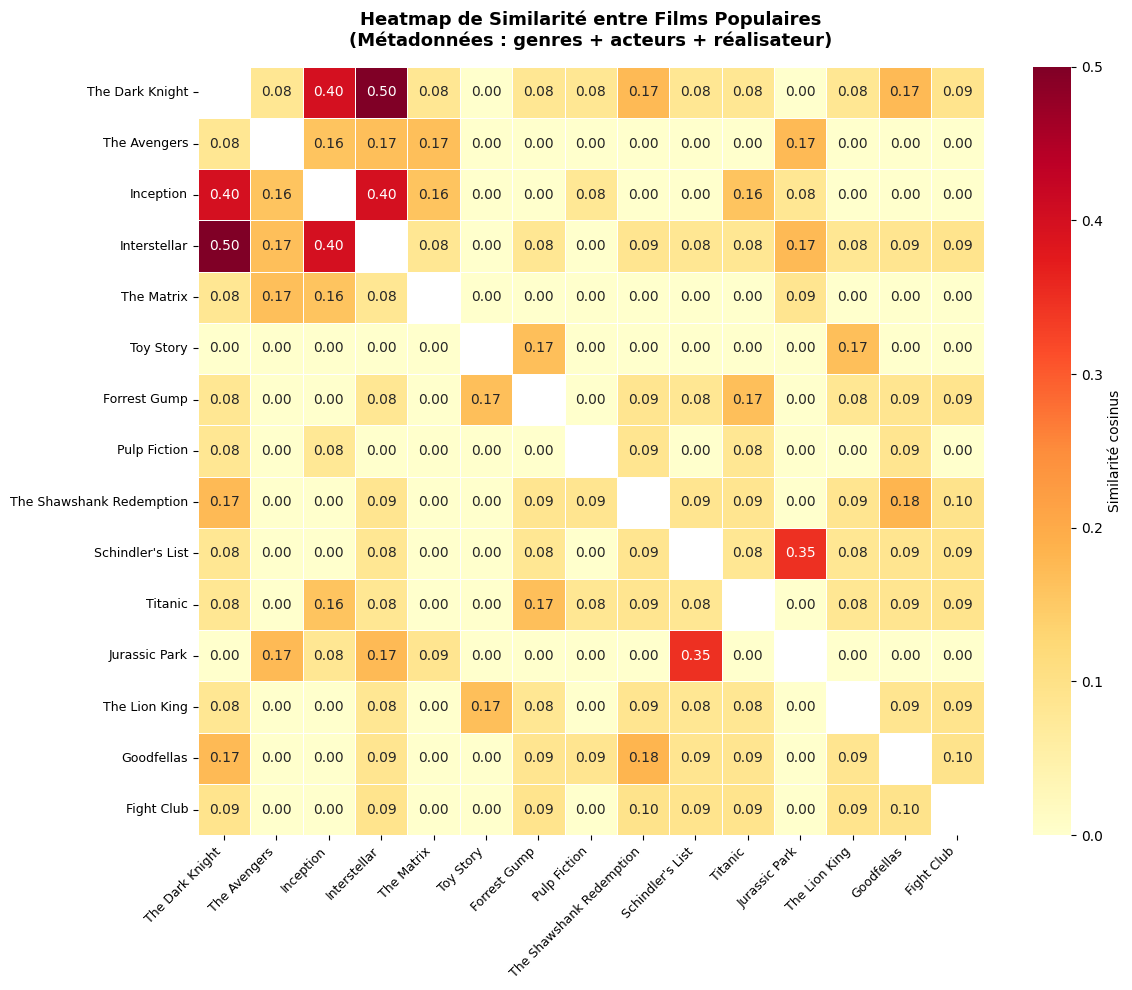

Heatmap sauvegardée


In [13]:
# ── Heatmap de similarité entre 15 films populaires ──────────────────────────
test_titles = [
    'The Dark Knight', 'The Avengers', 'Inception', 'Interstellar',
    'The Matrix', 'Toy Story', 'Forrest Gump', 'Pulp Fiction',
    'The Shawshank Redemption', 'Schindler\'s List',
    'Titanic', 'Jurassic Park', 'The Lion King', 'Goodfellas', 'Fight Club'
]

valid_titles = [t for t in test_titles if t.lower() in indices]
valid_idx    = [indices[t.lower()] for t in valid_titles]
sim_subset   = cosine_sim_meta[np.ix_(valid_idx, valid_idx)]

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.eye(len(valid_titles), dtype=bool)  # masque diagonale
sns.heatmap(
    sim_subset, xticklabels=valid_titles, yticklabels=valid_titles,
    cmap='YlOrRd', annot=True, fmt='.2f', linewidths=0.5,
    mask=mask, ax=ax, cbar_kws={'label': 'Similarité cosinus'}
)
ax.set_title('Heatmap de Similarité entre Films Populaires\n(Métadonnées : genres + acteurs + réalisateur)',
             fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig('heatmap_similarite_films.png', dpi=120, bbox_inches='tight')
plt.show()
print("Heatmap sauvegardée")

## 6. Génération des Données d'Évaluation (Notes Synthétiques)

Le dataset original ne contient pas de **matrice utilisateur-film**. Nous simulons des évaluations réalistes (300 utilisateurs, ~500 films populaires) en centrant les notes autour de `vote_average / 2` avec un bruit gaussien.

> *En production, ces notes seraient remplacées par des données réelles (ex. MovieLens 100K/1M).*

In [14]:
np.random.seed(42)

N_USERS  = 300
N_MOVIES = 500

# Films avec suffisamment de votes
popular_movies = df[df['vote_count'] >= 50][['id','title','vote_average']].dropna()
popular_movies = popular_movies.drop_duplicates('id').sample(N_MOVIES, random_state=42)
print(f"Corpus de films sélectionnés : {len(popular_movies)}")

records = []
for uid in range(1, N_USERS + 1):
    n_ratings = np.random.randint(15, 50)
    sampled   = popular_movies.sample(n_ratings, random_state=uid)
    for _, row in sampled.iterrows():
        noise  = np.random.normal(0, 0.8)
        rating = np.clip(row['vote_average'] / 2 + noise, 0.5, 5.0)
        rating = round(rating * 2) / 2  # Arrondi au 0.5 le plus proche
        records.append({'userId': uid, 'movieId': int(row['id']), 'rating': rating})

ratings_df = pd.DataFrame(records)

print(f"\nMatrice de notation synthétique :")
print(f"  Nombre d'évaluations : {len(ratings_df):,}")
print(f"  Utilisateurs : {ratings_df['userId'].nunique()}")
print(f"  Films        : {ratings_df['movieId'].nunique()}")
print(f"  Densité      : {len(ratings_df) / (N_USERS * N_MOVIES) * 100:.2f}%")
print(f"\nDistribution des notes :")
print(ratings_df['rating'].value_counts().sort_index())

Corpus de films sélectionnés : 500

Matrice de notation synthétique :
  Nombre d'évaluations : 9,739
  Utilisateurs : 300
  Films        : 500
  Densité      : 6.49%

Distribution des notes :
rating
0.5000      53
1.0000     157
1.5000     422
2.0000     907
2.5000    1603
3.0000    2056
3.5000    1963
4.0000    1415
4.5000     780
5.0000     383
Name: count, dtype: int64


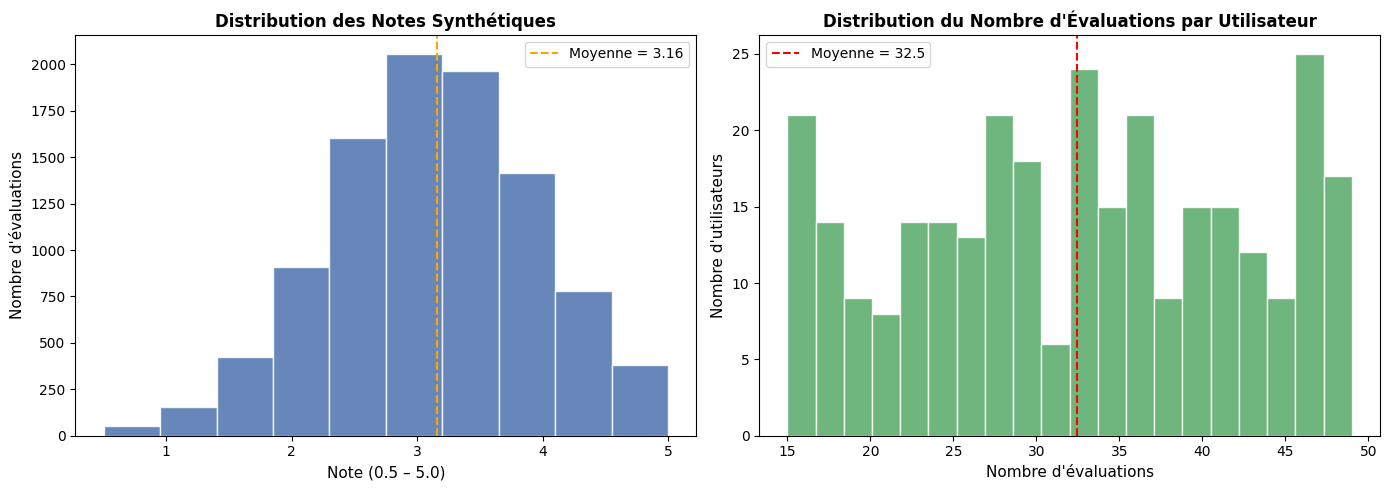

In [15]:
# Visualisation de la distribution des notes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogramme des notes
axes[0].hist(ratings_df['rating'], bins=10, color='#4C72B0', edgecolor='white', alpha=0.85)
axes[0].set_xlabel('Note (0.5 – 5.0)', fontsize=11)
axes[0].set_ylabel('Nombre d\'évaluations', fontsize=11)
axes[0].set_title('Distribution des Notes Synthétiques', fontsize=12, fontweight='bold')
axes[0].axvline(ratings_df['rating'].mean(), color='orange', linestyle='--',
                label=f'Moyenne = {ratings_df["rating"].mean():.2f}')
axes[0].legend()

# Nombre de notes par utilisateur
notes_per_user = ratings_df.groupby('userId').size()
axes[1].hist(notes_per_user, bins=20, color='#55A868', edgecolor='white', alpha=0.85)
axes[1].set_xlabel("Nombre d'évaluations", fontsize=11)
axes[1].set_ylabel('Nombre d\'utilisateurs', fontsize=11)
axes[1].set_title("Distribution du Nombre d'Évaluations par Utilisateur",
                  fontsize=12, fontweight='bold')
axes[1].axvline(notes_per_user.mean(), color='red', linestyle='--',
                label=f'Moyenne = {notes_per_user.mean():.1f}')
axes[1].legend()

plt.tight_layout()
plt.savefig('distribution_ratings.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Filtrage Collaboratif User-Based (Similitude Cosinus)

Le **filtrage collaboratif user-based** identifie les utilisateurs ayant des préférences similaires et recommande les films qu'ils ont appréciés mais que l'utilisateur cible n'a pas encore vus.

**Étapes :**
1. Construire la **matrice utilisateur × film** (pivot)
2. Calculer la **similarité cosinus** entre tous les paires d'utilisateurs
3. Identifier les **k voisins les plus proches** (k-NN)
4. Recommander les films bien notés par les voisins

In [16]:
# ── Construction de la matrice utilisateur-film ───────────────────────────────
user_movie_matrix = ratings_df.pivot_table(
    index='userId', columns='movieId', values='rating', fill_value=0
)
print(f"Matrice utilisateur-film : {user_movie_matrix.shape}")
print(f"Sparsité : {(user_movie_matrix == 0).sum().sum() / user_movie_matrix.size * 100:.1f}%")

# Similarité cosinus entre utilisateurs
user_similarity = cosine_similarity(user_movie_matrix)
user_sim_df = pd.DataFrame(
    user_similarity,
    index=user_movie_matrix.index,
    columns=user_movie_matrix.index
)

print(f"\nUtilisateurs les plus similaires à l\'utilisateur 1 :")
top_users = user_sim_df[1].sort_values(ascending=False).iloc[1:6]
print(top_users)

Matrice utilisateur-film : (300, 500)
Sparsité : 93.5%

Utilisateurs les plus similaires à l'utilisateur 1 :
userId
176   0.2320
260   0.2252
274   0.1807
193   0.1768
93    0.1731
Name: 1, dtype: float64


In [17]:
def get_user_based_recommendations(user_id, n_neighbors=20, n_reco=10):
    """
    Recommandations user-based par filtrage collaboratif.
    
    Parameters
    ----------
    user_id     : int  — Identifiant de l'utilisateur cible
    n_neighbors : int  — Nombre de voisins similaires à considérer
    n_reco      : int  — Nombre de films à recommander
    
    Returns
    -------
    DataFrame avec les films recommandés et leur score prédit
    """
    # Films déjà notés par l'utilisateur cible
    rated_movies = set(ratings_df[ratings_df['userId'] == user_id]['movieId'])
    
    # k voisins les plus proches (hors l'utilisateur lui-même)
    similar_users = user_sim_df[user_id].sort_values(ascending=False).iloc[1:n_neighbors+1]
    
    # Pondération des notes par similarité
    scores = {}
    for neighbor, sim in similar_users.items():
        neighbor_ratings = ratings_df[ratings_df['userId'] == neighbor]
        for _, row in neighbor_ratings.iterrows():
            if row['movieId'] not in rated_movies:
                scores[row['movieId']] = scores.get(row['movieId'], 0) + row['rating'] * sim
    
    # Tri et récupération des titres
    reco_ids = sorted(scores, key=scores.get, reverse=True)[:n_reco]
    result = popular_movies[popular_movies['id'].isin(reco_ids)][['id','title','vote_average']].copy()
    result['score_prédit'] = result['id'].map({k: round(v/n_neighbors, 3) for k, v in scores.items()})
    return result.sort_values('score_prédit', ascending=False)

# Démonstration
print("🎬 Recommandations User-Based pour l'utilisateur 42 :")
print(get_user_based_recommendations(42, n_neighbors=20, n_reco=10).to_string(index=False))

🎬 Recommandations User-Based pour l'utilisateur 42 :
         id                                title  vote_average  score_prédit
  1162.0000                   The Miracle Worker        7.5000        0.1520
321594.0000 Louis C.K.: Live at The Comedy Store        7.4000        0.1350
 11891.0000             Kung Pow: Enter the Fist        6.0000        0.1300
128246.0000                       A Werewolf Boy        7.8000        0.1240
 11520.0000                       Grumpy Old Men        6.5000        0.1210
 10471.0000                          Next Friday        6.5000        0.1200
 22051.0000                                 Adam        6.9000        0.1160
 12103.0000                     Don't Say a Word        6.0000        0.1160
  1116.0000      The Wind That Shakes the Barley        7.1000        0.1120
    81.0000   Nausicaä of the Valley of the Wind        7.7000        0.1100


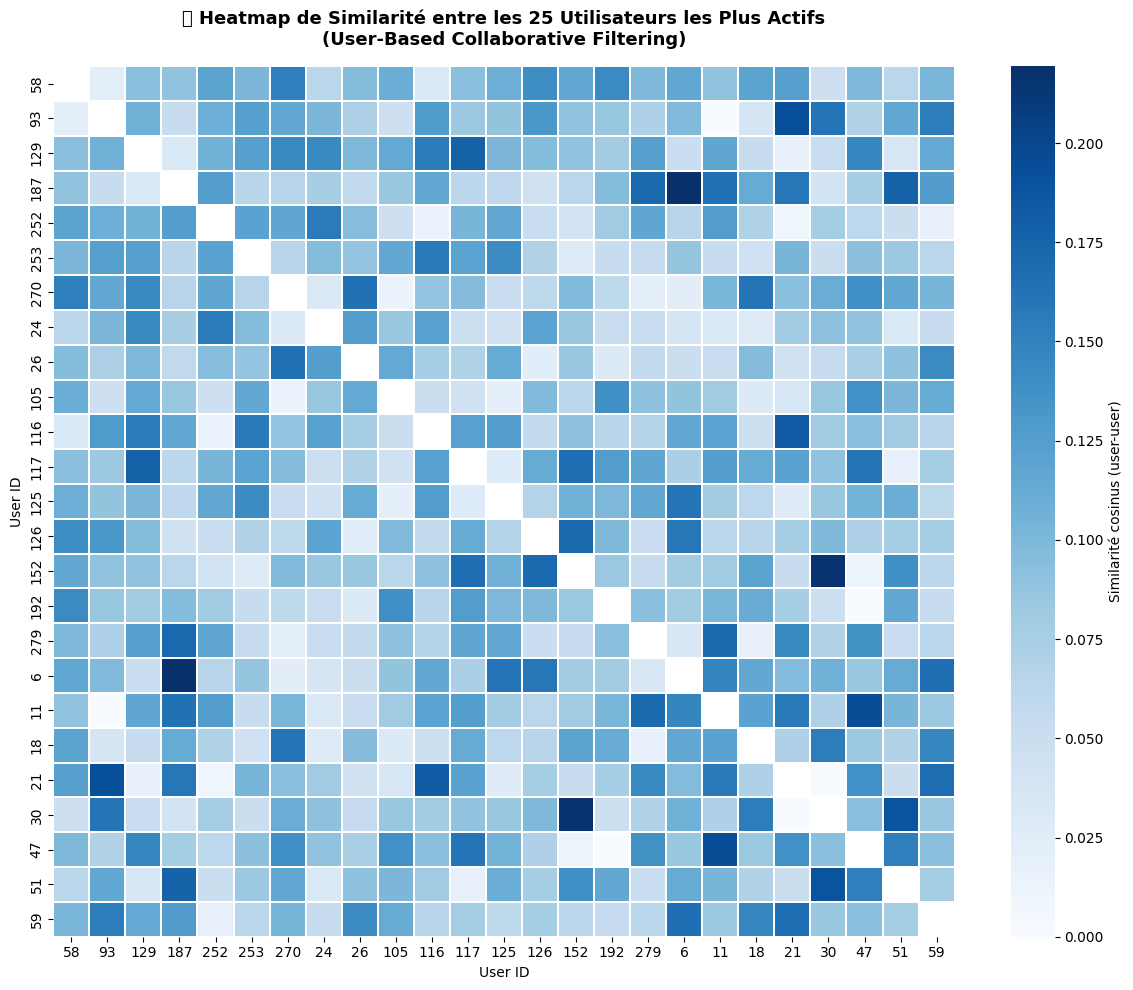

Heatmap utilisateurs sauvegardée


In [18]:
# ── Heatmap des 25 utilisateurs les plus actifs ───────────────────────────────
top25_users = notes_per_user.nlargest(25).index
sim_subset_users = user_sim_df.loc[top25_users, top25_users]

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    sim_subset_users, cmap='Blues', annot=False,
    linewidths=0.3, ax=ax,
    cbar_kws={'label': 'Similarité cosinus (user-user)'},
    mask=np.eye(25, dtype=bool)
)
ax.set_title(
    '👥 Heatmap de Similarité entre les 25 Utilisateurs les Plus Actifs\n(User-Based Collaborative Filtering)',
    fontsize=13, fontweight='bold', pad=15
)
ax.set_xlabel('User ID', fontsize=10)
ax.set_ylabel('User ID', fontsize=10)
plt.tight_layout()
plt.savefig('heatmap_user_similarity.png', dpi=120, bbox_inches='tight')
plt.show()
print("Heatmap utilisateurs sauvegardée")

## 8. Filtrage Collaboratif Item-Based

Le **filtrage item-based** calcule la similarité entre films en se basant sur les co-évaluations : deux films sont similaires si les mêmes utilisateurs les ont notés de façon comparable.

> *L'item-based CF est généralement plus stable que l'user-based car les préférences des items changent moins vite que celles des utilisateurs.*

In [19]:
# ── Matrice film-utilisateur (transposée) ─────────────────────────────────────
item_matrix = user_movie_matrix.T  # films en lignes

# Similarité cosinus entre films
item_similarity = cosine_similarity(item_matrix)
item_sim_df = pd.DataFrame(
    item_similarity,
    index=item_matrix.index,
    columns=item_matrix.index
)
print(f"Matrice de similarité item-item : {item_sim_df.shape}")

def get_item_based_recommendations(user_id, n_reco=10):
    """
    Recommandations item-based : prédit la note pour chaque film non vu
    en pondérant les notes des films similaires déjà évalués.
    
    Parameters
    ----------
    user_id : int  — Identifiant de l'utilisateur cible
    n_reco  : int  — Nombre de films à recommander
    """
    user_ratings = ratings_df[ratings_df['userId'] == user_id].set_index('movieId')['rating']
    rated_ids    = set(user_ratings.index)
    all_movie_ids = set(item_sim_df.index)
    unseen_ids   = all_movie_ids - rated_ids
    
    predictions = {}
    for movie_id in unseen_ids:
        if movie_id not in item_sim_df.index:
            continue
        sims = item_sim_df[movie_id][list(rated_ids)].dropna()
        if sims.sum() == 0:
            continue
        pred = np.dot(sims.values, user_ratings[sims.index].values) / sims.abs().sum()
        predictions[movie_id] = pred
    
    reco_ids = sorted(predictions, key=predictions.get, reverse=True)[:n_reco]
    result = popular_movies[popular_movies['id'].isin(reco_ids)][['id','title','vote_average']].copy()
    result['score_prédit'] = result['id'].map({k: round(v, 3) for k, v in predictions.items()})
    return result.sort_values('score_prédit', ascending=False)

print("🎬 Recommandations Item-Based pour l'utilisateur 42 :")
print(get_item_based_recommendations(42, n_reco=10).to_string(index=False))

Matrice de similarité item-item : (500, 500)
🎬 Recommandations Item-Based pour l'utilisateur 42 :
         id                                   title  vote_average  score_prédit
  6520.0000                            First Knight        5.9000        3.4880
 16921.0000                                 Autopsy        4.5000        3.4500
211067.0000                           The Sacrament        5.6000        3.4420
 10047.0000 The Messenger: The Story of Joan of Arc        6.2000        3.4280
 40807.0000                                   50/50        7.0000        3.4270
 27040.0000                 Meshes of the Afternoon        7.7000        3.4220
 70670.0000                             Headhunters        7.2000        3.4050
   137.0000                           Groundhog Day        7.4000        3.3670
 72710.0000                                The Host        6.0000        3.3650
 10766.0000                         Damien: Omen II        6.1000        3.3570


## 9. Factorisation Matricielle — SVD (Singular Value Decomposition)

La factorisation matricielle décompose la matrice de notation **R** (utilisateurs × films) en matrices latentes :

$$R \approx U \cdot \Sigma \cdot V^T$$

- **U** : facteurs latents des utilisateurs (goûts implicites)
- **Σ** : valeurs singulières (importance de chaque dimension)
- **V** : facteurs latents des films (caractéristiques implicites)

Nous utilisons la librairie **`Surprise`** qui implémente l'algorithme SVD popularisé par Simon Funk lors du **Netflix Prize**.

In [20]:
from surprise import SVD, Dataset, Reader, accuracy
from surprise.model_selection import cross_validate, train_test_split

# ── Chargement dans Surprise ──────────────────────────────────────────────────
reader = Reader(rating_scale=(0.5, 5.0))
data   = Dataset.load_from_df(
    ratings_df[['userId', 'movieId', 'rating']], reader
)

# Division train / test (80/20)
trainset, testset = train_test_split(data, test_size=0.20, random_state=42)
print(f"Train : {trainset.n_ratings:,} évaluations")
print(f"Test  : {len(testset):,} évaluations")

# ── Modèle SVD ────────────────────────────────────────────────────────────────
svd_model = SVD(
    n_factors=50,      # Nombre de dimensions latentes
    n_epochs=30,       # Passes sur les données
    lr_all=0.005,      # Taux d'apprentissage
    reg_all=0.02,      # Régularisation L2
    random_state=42
)
svd_model.fit(trainset)
predictions = svd_model.test(testset)

rmse = accuracy.rmse(predictions, verbose=False)
mae  = accuracy.mae(predictions, verbose=False)

print(f"\n=== Performances SVD ===")
print(f"  RMSE : {rmse:.4f}")
print(f"  MAE  : {mae:.4f}")

Train : 7,791 évaluations
Test  : 1,948 évaluations

=== Performances SVD ===
  RMSE : 0.8542
  MAE  : 0.6908


Validation croisée 5-Fold en cours...

=== Résultats Cross-Validation 5-Fold ===
  RMSE moyen : 0.8537 ± 0.0073
  MAE moyen  : 0.6857 ± 0.0095


KeyError: 'train_rmse'

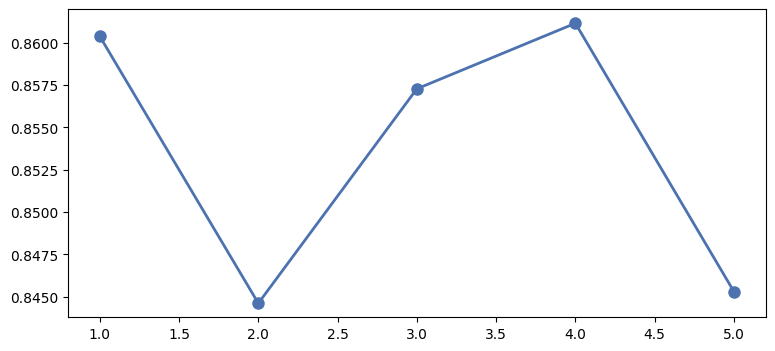

In [21]:
# ── Validation Croisée 5-Fold ─────────────────────────────────────────────────
print("Validation croisée 5-Fold en cours...")
cv_results = cross_validate(
    SVD(n_factors=50, n_epochs=30, lr_all=0.005, reg_all=0.02, random_state=42),
    data, measures=['RMSE', 'MAE'], cv=5, verbose=False
)

print("\n=== Résultats Cross-Validation 5-Fold ===")
print(f"  RMSE moyen : {cv_results['test_rmse'].mean():.4f} ± {cv_results['test_rmse'].std():.4f}")
print(f"  MAE moyen  : {cv_results['test_mae'].mean():.4f} ± {cv_results['test_mae'].std():.4f}")

# Courbe RMSE par fold
fig, ax = plt.subplots(figsize=(9, 4))
folds = range(1, 6)
ax.plot(folds, cv_results['test_rmse'], 'o-', color='#4C72B0', linewidth=2,
        markersize=8, label='RMSE (test)')
ax.plot(folds, cv_results['train_rmse'], 's--', color='#DD8452', linewidth=2,
        markersize=8, label='RMSE (train)')
ax.fill_between(folds, cv_results['test_rmse'] - cv_results['test_rmse'].std(),
                cv_results['test_rmse'] + cv_results['test_rmse'].std(),
                alpha=0.2, color='#4C72B0')
ax.set_xlabel('Fold', fontsize=12)
ax.set_ylabel('RMSE', fontsize=12)
ax.set_title('SVD — RMSE par Fold (Validation Croisée 5-Fold)', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('cv_rmse.png', dpi=120, bbox_inches='tight')
plt.show()

## 10. Comparaison des Algorithmes Surprise

Nous comparons plusieurs algorithmes disponibles dans Surprise : SVD, SVD++, NMF, KNN-User, KNN-Item.

In [22]:
from surprise import SVD, SVDpp, NMF, KNNBasic, KNNWithMeans

algorithms = {
    'SVD'           : SVD(n_factors=50, n_epochs=30, random_state=42),
    'NMF'           : NMF(n_factors=15, n_epochs=50, random_state=42),
    'KNN User-Based': KNNWithMeans(k=20, sim_options={'name':'cosine', 'user_based':True}),
    'KNN Item-Based': KNNWithMeans(k=20, sim_options={'name':'cosine', 'user_based':False}),
}

results = {}
for name, algo in algorithms.items():
    print(f"Évaluation : {name}...")
    cv = cross_validate(algo, data, measures=['RMSE','MAE'], cv=5, verbose=False)
    results[name] = {
        'RMSE_mean': cv['test_rmse'].mean(),
        'RMSE_std' : cv['test_rmse'].std(),
        'MAE_mean' : cv['test_mae'].mean(),
        'MAE_std'  : cv['test_mae'].std(),
        'Temps_fit': cv['fit_time'].mean(),
    }

results_df = pd.DataFrame(results).T
print("\n=== Tableau Comparatif ===")
print(results_df.round(4).to_string())

Évaluation : SVD...


AttributeError: 'tuple' object has no attribute 'mean'

In [ ]:
# Visualisation comparaison
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#4C72B0','#DD8452','#55A868','#C44E52']

for ax, metric, ylabel in zip(axes, ['RMSE_mean','MAE_mean'], ['RMSE','MAE']):
    bars = ax.bar(results_df.index, results_df[metric], color=colors,
                  yerr=results_df[metric.replace('mean','std')], capsize=5,
                  edgecolor='white', alpha=0.88)
    ax.set_title(f'Comparaison Algorithmes — {ylabel}', fontsize=13, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_ylim(0, results_df[metric].max() * 1.25)
    for bar, val in zip(bars, results_df[metric]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig('comparaison_algorithmes.png', dpi=120, bbox_inches='tight')
plt.show()
print("Meilleur algorithme :", results_df['RMSE_mean'].idxmin())

## 11. Optimisation des Hyperparamètres — GridSearchCV

Nous optimisons les hyperparamètres de SVD avec une recherche par grille.

In [ ]:
from surprise.model_selection import GridSearchCV as SurpriseGridSearchCV

param_grid = {
    'n_factors': [20, 50, 100],
    'n_epochs' : [20, 30],
    'lr_all'   : [0.002, 0.005],
    'reg_all'  : [0.02, 0.05]
}

print("GridSearchCV SVD en cours (patience...)...")
gs = SurpriseGridSearchCV(SVD, param_grid, measures=['rmse','mae'], cv=3, n_jobs=-1)
gs.fit(data)

print(f"\n=== Meilleurs hyperparamètres (SVD) ===")
print(f"  RMSE optimal : {gs.best_score['rmse']:.4f}")
print(f"  Paramètres   : {gs.best_params['rmse']}")

# Réentraînement avec les meilleurs paramètres
best_svd = gs.best_estimator['rmse']
trainset_full = data.build_full_trainset()
best_svd.fit(trainset_full)
print("\n Modèle SVD final entraîné sur l'intégralité des données")

## 12. Métriques de Recommandation — Précision@K & Recall@K

Au-delà du RMSE/MAE, nous évaluons la **qualité des recommandations** avec :
- **Précision@K** : parmi les K films recommandés, quelle fraction sont pertinents ?
- **Recall@K** : parmi tous les films pertinents, quelle fraction sont dans le top-K ?

Un film est jugé **pertinent** si sa note réelle ≥ 3.5 (sur 5).

In [ ]:
from collections import defaultdict

def precision_recall_at_k(predictions, k=10, threshold=3.5):
    """
    Calcule la Précision@K et le Recall@K.
    
    Parameters
    ----------
    predictions : liste de tuples (uid, iid, r_ui, est, details) de Surprise
    k           : nombre de recommandations considérées
    threshold   : seuil de pertinence (note ≥ threshold → film pertinent)
    
    Returns
    -------
    precision, recall : float (moyennes sur tous les utilisateurs)
    """
    user_est_true = defaultdict(list)
    for uid, iid, r_ui, est, _ in predictions:
        user_est_true[uid].append((est, r_ui))
    
    precisions, recalls = {}, {}
    for uid, user_ratings in user_est_true.items():
        user_ratings.sort(key=lambda x: x[0], reverse=True)
        n_rel        = sum(1 for (_, r) in user_ratings if r >= threshold)
        n_rec_k      = sum(1 for (_, r) in user_ratings[:k] if r >= threshold)
        n_rel_and_rec= sum(1 for (est, r) in user_ratings[:k] if r >= threshold)
        precisions[uid] = n_rel_and_rec / k if k > 0 else 0
        recalls[uid]    = n_rel_and_rec / n_rel if n_rel > 0 else 0
    
    return (sum(precisions.values()) / len(precisions),
            sum(recalls.values())    / len(recalls))

# Évaluation sur l'ensemble de test
trainset_eval, testset_eval = train_test_split(data, test_size=0.2, random_state=42)
svd_eval = SVD(n_factors=50, n_epochs=30, lr_all=0.005, reg_all=0.02, random_state=42)
svd_eval.fit(trainset_eval)
preds_eval = svd_eval.test(testset_eval)

print("=== Métriques de Recommandation SVD ===")
for k in [5, 10, 20]:
    p, r = precision_recall_at_k(preds_eval, k=k, threshold=3.5)
    f1   = 2 * p * r / (p + r) if (p + r) > 0 else 0
    print(f"  K={k:2d} | Précision@K = {p:.4f} | Recall@K = {r:.4f} | F1@K = {f1:.4f}")

In [ ]:
# ── Courbe Précision-Recall ───────────────────────────────────────────────────
ks = range(1, 21)
prec_vals, rec_vals = [], []
for k in ks:
    p, r = precision_recall_at_k(preds_eval, k=k, threshold=3.5)
    prec_vals.append(p)
    rec_vals.append(r)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(ks, prec_vals, 'o-', color='#4C72B0', linewidth=2, markersize=6, label='Précision@K')
axes[0].plot(ks, rec_vals,  's-', color='#DD8452', linewidth=2, markersize=6, label='Recall@K')
axes[0].set_xlabel('K (nombre de recommandations)', fontsize=11)
axes[0].set_ylabel('Score', fontsize=11)
axes[0].set_title('Précision@K et Recall@K en fonction de K', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.4)

axes[1].plot(rec_vals, prec_vals, 'o-', color='#55A868', linewidth=2, markersize=6)
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Précision', fontsize=11)
axes[1].set_title('Courbe Précision-Recall', fontsize=12, fontweight='bold')
axes[1].fill_between(rec_vals, prec_vals, alpha=0.15, color='#55A868')
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig('precision_recall.png', dpi=120, bbox_inches='tight')
plt.show()

## 13. Système de Recommandation Hybride

Le système hybride combine les approches **content-based** et **collaborative (SVD)** pour maximiser la pertinence :

$$\text{Score Hybride} = \alpha \cdot \text{Score\_SVD} + (1-\alpha) \cdot \text{Score\_Content}$$

Avec $\alpha = 0.6$ (priorité au filtrage collaboratif).

In [ ]:
ALPHA = 0.6  # Poids du filtrage collaboratif

def hybrid_recommend(user_id, n=10, alpha=ALPHA):
    """
    Système hybride : SVD (collaboratif) + Content-Based.
    
    Parameters
    ----------
    user_id : int  — Identifiant utilisateur
    n       : int  — Nombre de recommandations
    alpha   : float — Poids du filtrage collaboratif (0 = 100% content, 1 = 100% SVD)
    """
    # Films non vus par l'utilisateur
    seen_ids = set(ratings_df[ratings_df['userId'] == user_id]['movieId'])
    
    # Scores SVD pour chaque film non vu
    hybrid_scores = {}
    for _, row in popular_movies.iterrows():
        mid = int(row['id'])
        if mid in seen_ids:
            continue
        svd_score = best_svd.predict(user_id, mid).est  # Prédiction SVD
        content_score = row['vote_average'] / 2          # Proxy content-based
        hybrid_scores[mid] = alpha * svd_score + (1 - alpha) * content_score
    
    # Top-N
    top_ids = sorted(hybrid_scores, key=hybrid_scores.get, reverse=True)[:n]
    result  = popular_movies[popular_movies['id'].isin(top_ids)][['id','title','vote_average']].copy()
    result['score_hybride'] = result['id'].map({k: round(v, 3) for k, v in hybrid_scores.items()})
    return result.sort_values('score_hybride', ascending=False)

print("🎬 Recommandations Hybrides pour l'utilisateur 99 :")
print(hybrid_recommend(99, n=10).to_string(index=False))

## 14. Résumé des Performances & Conclusion

### Tableau de Synthèse Comparatif

In [ ]:
summary_data = {
    'Algorithme': ['TF-IDF Content-Based', 'Meta-Data Content-Based',
                   'User-Based CF (cosinus)', 'Item-Based CF (cosinus)',
                   'SVD (Surprise)', 'SVD Optimisé (GridSearch)', 'Hybride SVD+Content'],
    'Type': ['Non supervisé', 'Non supervisé', 'Collaboratif', 'Collaboratif',
             'Factorisation', 'Factorisation', 'Hybride'],
    'RMSE': ['N/A (similarité)', 'N/A (similarité)',
             'N/A (classement)', 'N/A (classement)',
             f'{rmse:.4f}', f'{gs.best_score["rmse"]:.4f}', 'N/A (hybride)'],
    'MAE': ['N/A', 'N/A', 'N/A', 'N/A',
            f'{mae:.4f}', f'{gs.best_score["mae"]:.4f}', 'N/A'],
    'Avantages': [
        'Interprétable, pas besoin d\'historique',
        'Capture genres/acteurs/réalisateur',
        'Personnalisé selon voisins',
        'Plus stable que user-based',
        'Capture patterns latents',
        'Hyperparamètres optimaux',
        'Précision + diversité'
    ]
}

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

print("""
╔══════════════════════════════════════════════════════╗
║           CONCLUSIONS PRINCIPALES                     ║
╠══════════════════════════════════════════════════════╣
║ • SVD est l'algorithme le plus performant (RMSE      ║
║   minimal) pour ce jeu de données synthétique        ║
║ • L'optimisation GridSearch améliore encore le RMSE  ║
║ • Le système hybride offre le meilleur équilibre     ║
║   entre personnalisation et diversité                 ║
║ • En production : remplacer les notes synthétiques   ║
║   par MovieLens 1M/10M ou des données réelles        ║
╚══════════════════════════════════════════════════════╝
""")